# 01 · Exploración de datos
Distribución de clases, tamaños de imagen y ejemplos.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from src.train import load_config
cfg = load_config("configs/baseline.yaml")
RAW = cfg["data"]["raw_dir"]

I0000 00:00:1792858897.415236   16563 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


87000 imágenes, 29 clases


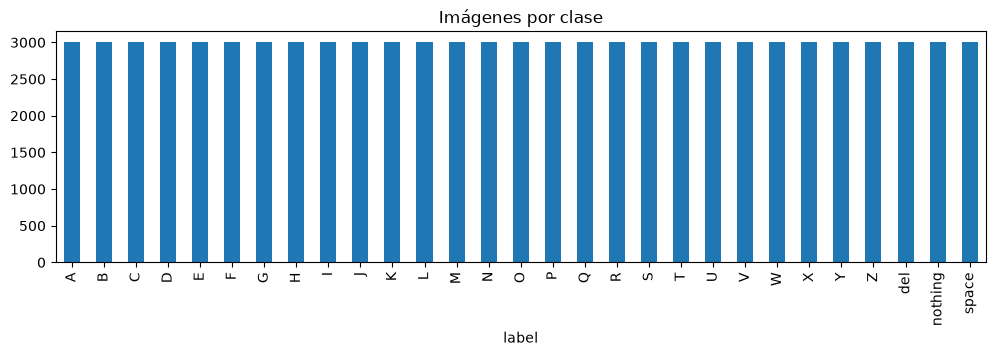

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src.data import list_images

df = list_images(RAW)
counts = df.label.value_counts().sort_index()
print(f"{len(df)} imágenes, {counts.size} clases")
counts.plot.bar(figsize=(12, 3), title="Imágenes por clase")
plt.show()

In [3]:
from PIL import Image

sizes = {Image.open(f"{RAW}/{p}").size for p in df.sample(200, random_state=0).path}
print("Tamaños en una muestra de 200:", sizes)

Tamaños en una muestra de 200: {(200, 200)}


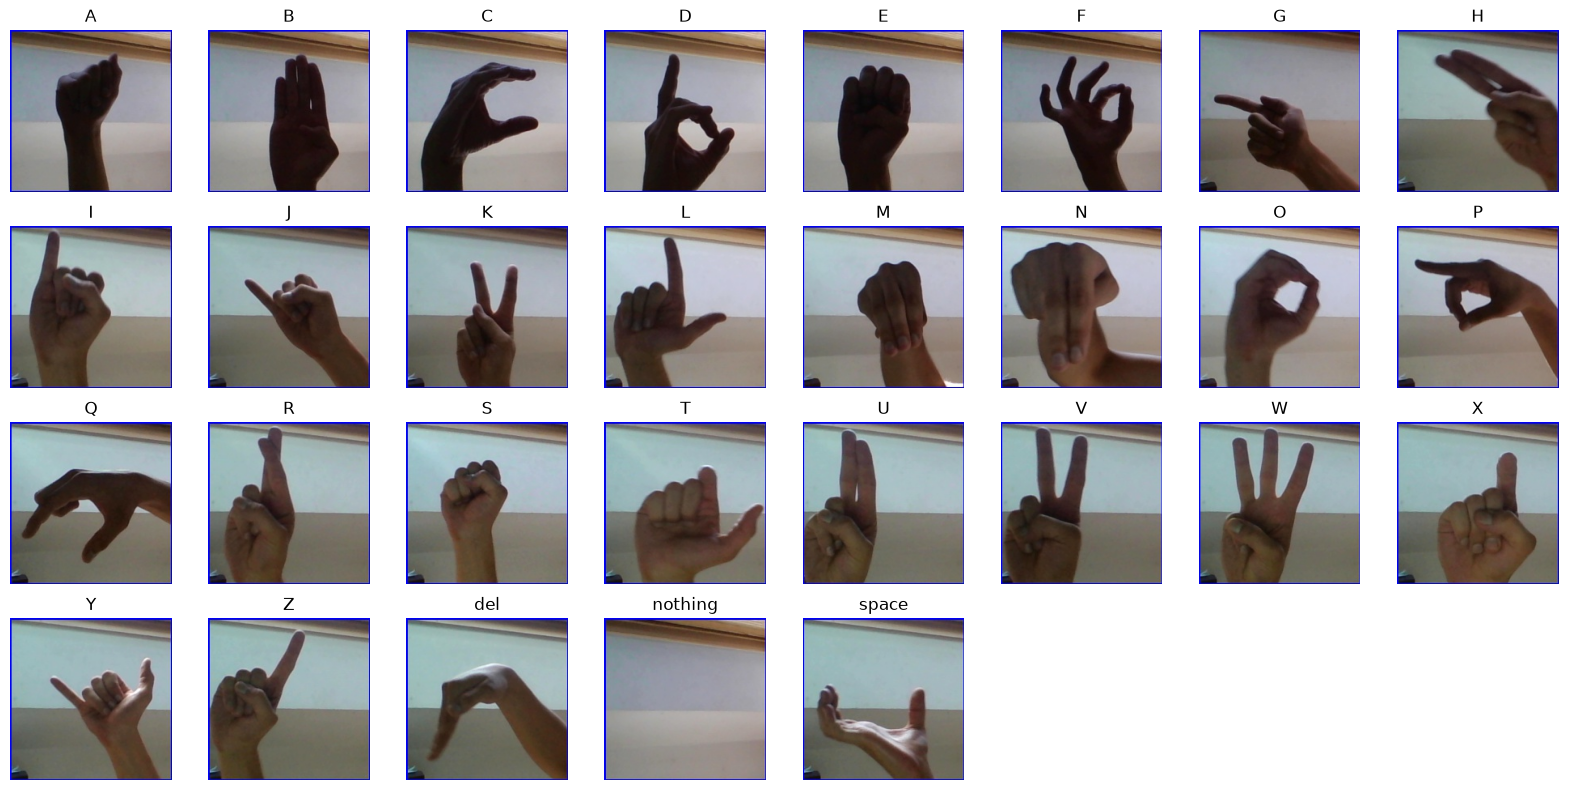

In [4]:
classes = sorted(df.label.unique())
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for ax, c in zip(axes.flat, classes):
    ax.imshow(Image.open(f"{RAW}/{df[df.label == c].path.iloc[0]}"))
    ax.set_title(c)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()